# EDA: NYC yellow taxi, Jan-Apr 2020

Schema/dtypes, data-quality issues, pickup volume over time, zone selection, and a first look at the lag/calendar signals the forecast contract proposes as features.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
import yaml


def find_root(start: Path) -> Path:
    p = start.resolve()
    while not (p / "pyproject.toml").exists():
        p = p.parent
    return p


ROOT = find_root(Path.cwd())
RAW_DIR = ROOT / "data" / "raw"
params = yaml.safe_load((ROOT / "params.yaml").read_text())
months = params["data"]["months"]
taxi_type = params["data"]["taxi_type"]
n_zones = params["data"]["n_zones"]
periods = {k: (v["start"], v["end"]) for k, v in params["periods"].items()}
files = {m: RAW_DIR / f"{taxi_type}_tripdata_{m}.parquet" for m in months}
periods

{'warmup': ('2020-01-01', '2020-01-08'),
 'train': ('2020-01-08', '2020-02-03'),
 'calibration': ('2020-02-03', '2020-02-17'),
 'test': ('2020-02-17', '2020-03-01'),
 'replay': ('2020-03-01', '2020-05-01')}

In [2]:
zones = pd.read_csv(ROOT / "data" / "external" / "taxi_zone_lookup.csv")
print(zones.shape)
zones.head()

(265, 4)


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


## Schema and dtypes across months

TLC has changed this schema across years (e.g. added `congestion_surcharge`, later `airport_fee`). Check it's actually consistent across our four files before assuming one schema.

In [3]:
schemas = {}
for m, f in files.items():
    pf = pq.ParquetFile(f)
    schemas[m] = {field.name: str(field.type) for field in pf.schema_arrow}

all_cols = sorted(set().union(*[set(s) for s in schemas.values()]))
schema_df = pd.DataFrame(
    {m: [schemas[m].get(c, "MISSING") for c in all_cols] for m in months},
    index=all_cols,
)
schema_df

,2020-01,2020-02,2020-03,2020-04
DOLocationID,int64,int64,int64,int64
PULocationID,int64,int64,int64,int64
RatecodeID,double,double,double,double
VendorID,int64,int64,int64,int64
airport_fee,null,null,null,null
congestion_surcharge,double,double,double,double
extra,double,double,double,double
fare_amount,double,double,double,double
improvement_surcharge,double,double,double,double
mta_tax,double,double,double,double


## Row counts and file sizes

Fast metadata-only read, no full load yet.

In [4]:
counts = {}
for m, f in files.items():
    pf = pq.ParquetFile(f)
    counts[m] = {
        "rows": pf.metadata.num_rows,
        "size_mb": round(f.stat().st_size / 1e6, 1),
    }
pd.DataFrame(counts).T

,rows,size_mb
2020-01,6405008.0,93.6
2020-02,6299367.0,92.1
2020-03,3007687.0,44.4
2020-04,238073.0,4.4


## Load a working sample

Only the columns the forecast contract actually needs (pickup/dropoff time, zone IDs, plus a few diagnostic-only fields to check cleaning decisions): `passenger_count`, `trip_distance`, `fare_amount`.

In [5]:
cols = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "passenger_count",
    "trip_distance",
    "fare_amount",
]
frames = []
for m, f in files.items():
    df = pd.read_parquet(f, columns=cols)
    df["source_month"] = m
    frames.append(df)
trips = pd.concat(frames, ignore_index=True)
del frames
trips.dtypes

tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
PULocationID                      int64
DOLocationID                      int64
passenger_count                 float64
trip_distance                   float64
fare_amount                     float64
source_month                        str
dtype: object

## Data quality checks

What might need cleaning before aggregation, and why (per the forecast contract: count valid pickups, don't drop a trip just because fare/distance looks odd).

In [6]:
n = len(trips)
checks = {
    "total_rows": n,
    "null_pickup_dt": trips.tpep_pickup_datetime.isna().sum(),
    "null_PULocationID": trips.PULocationID.isna().sum(),
    "dropoff_before_pickup": (
        trips.tpep_dropoff_datetime < trips.tpep_pickup_datetime
    ).sum(),
    "zero_or_neg_trip_distance": (trips.trip_distance <= 0).sum(),
    "zero_or_neg_fare": (trips.fare_amount <= 0).sum(),
    "PULocationID_not_in_zone_lookup": (
        ~trips.PULocationID.isin(zones.LocationID)
    ).sum(),
    "fully_duplicate_rows": trips.duplicated().sum(),
}
pd.Series(checks)

total_rows                         15950135
null_pickup_dt                            0
null_PULocationID                         0
dropoff_before_pickup                   221
zero_or_neg_trip_distance            168306
zero_or_neg_fare                      58551
PULocationID_not_in_zone_lookup           0
fully_duplicate_rows                  12954
dtype: int64

In [7]:
# Per-month pickup timestamp range: TLC files sometimes contain a few rows
# stamped outside the nominal month (data-entry errors) -- check, don't assume.
trips.groupby("source_month").tpep_pickup_datetime.agg(["min", "max"])

,min,max
source_month,,
2020-01,2003-01-01 00:07:17,2021-01-02 01:12:10
2020-02,2008-12-31 22:20:23,2020-07-11 12:57:52
2020-03,2008-12-31 23:02:19,2020-08-27 15:16:15
2020-04,2009-01-01 01:11:17,2020-04-30 23:59:42


## Quarantine out-of-range timestamps

The range check above found pickups stamped as early as 2003 and as late as 2021 -- a real TLC data-entry defect, not a fluke. Apply this filter once, here, so every cell below (daily volume, zone ranking, zone-hour aggregation, feature correlations) sees already-clean data instead of each needing its own filter.

In [8]:
window_start = pd.Timestamp(periods["warmup"][0])
window_end = pd.Timestamp(periods["replay"][1])
in_window = (trips.tpep_pickup_datetime >= window_start) & (
    trips.tpep_pickup_datetime < window_end
)
print(
    f"quarantining {(~in_window).sum()} of {len(trips)} rows outside [{window_start.date()}, {window_end.date()})"
)
trips = trips.loc[in_window].reset_index(drop=True)

quarantining 258 of 15950135 rows outside [2020-01-01, 2020-05-01)


## Pickup volume over time

Daily pickup counts across all zones -- this is where the demand collapse should become visible, independent of any single zone's behavior.

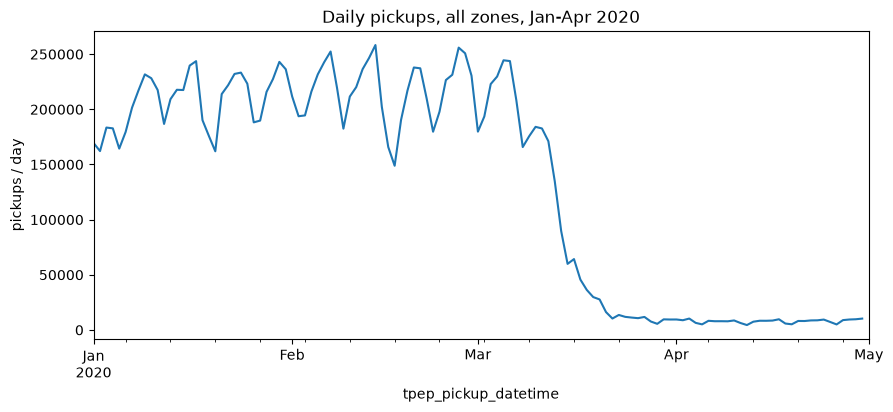

In [9]:
daily = trips.set_index("tpep_pickup_datetime").resample("1D").size()
fig, ax = plt.subplots(figsize=(10, 4))
daily.plot(ax=ax)
ax.set_xlim(window_start, window_end)
ax.set_title("Daily pickups, all zones, Jan-Apr 2020")
ax.set_ylabel("pickups / day")
plt.show()

## Zones

The forecast contract says: select 20 zones by **training-period** pickup volume only, then freeze them. Compute that now, not on the full dataset.

In [10]:
train_start, train_end = periods["train"]
train_mask = (trips.tpep_pickup_datetime >= train_start) & (
    trips.tpep_pickup_datetime < train_end
)
train_counts = trips.loc[train_mask, "PULocationID"].value_counts()
top_zones = train_counts.head(n_zones)
top_zones_named = (
    top_zones.rename("pickups")
    .to_frame()
    .merge(zones.set_index("LocationID"), left_index=True, right_index=True, how="left")
)
top_zones_named

,pickups,Borough,Zone,service_zone
PULocationID,,,,
237,255754,Manhattan,Upper East Side South,Yellow Zone
161,243682,Manhattan,Midtown Center,Yellow Zone
236,238450,Manhattan,Upper East Side North,Yellow Zone
162,205258,Manhattan,Midtown East,Yellow Zone
230,197033,Manhattan,Times Sq/Theatre District,Yellow Zone
186,196933,Manhattan,Penn Station/Madison Sq West,Yellow Zone
132,173310,Queens,JFK Airport,Airports
170,169380,Manhattan,Murray Hill,Yellow Zone
142,167776,Manhattan,Lincoln Square East,Yellow Zone


/tmp/ipykernel_2150/887696083.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels, rotation=75, ha="right")


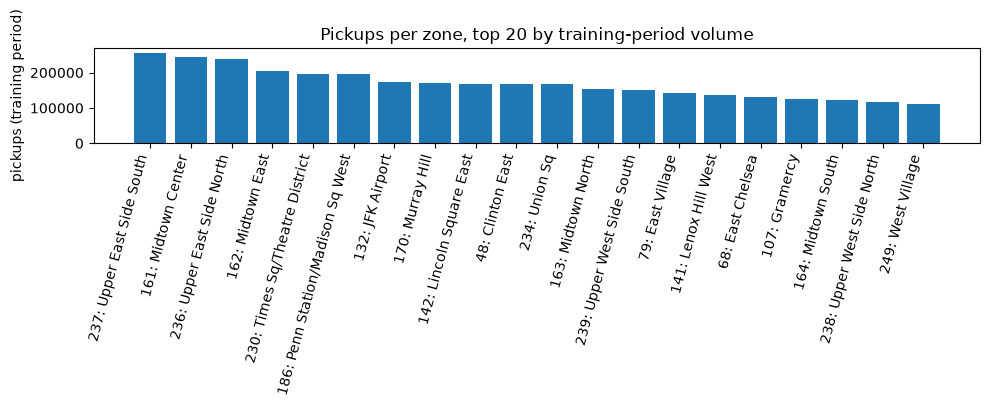

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = [
    f"{zid}: {name}" for zid, name in zip(top_zones_named.index, top_zones_named.Zone)
]
ax.bar(labels, top_zones_named.pickups)
ax.set_xticklabels(labels, rotation=75, ha="right")
ax.set_ylabel("pickups (training period)")
ax.set_title(f"Pickups per zone, top {n_zones} by training-period volume")
plt.tight_layout()
plt.show()

In [12]:
# Sanity: do the top zones include the known non-geographic placeholder IDs
# (264 = "Unknown", 265 = "N/A" in the TLC lookup)? Those should NOT end up
# in the frozen zone list.
top_zones_named[top_zones_named.index.isin([264, 265])]

,pickups,Borough,Zone,service_zone
PULocationID,,,,


## Candidate feature signals

For the top training-period zones, aggregate to zone-hour counts and look at hour-of-day / day-of-week patterns, plus lag autocorrelation -- this is what justifies the lag/rolling features the contract proposes (1h, 2h, 3h, 24h, 168h lags; 3h/24h/168h rolling means).

In [13]:
selected_zone_ids = top_zones.index.tolist()
sel = trips[trips.PULocationID.isin(selected_zone_ids)].copy()
sel["hour"] = sel.tpep_pickup_datetime.dt.floor("h")
zone_hour = sel.groupby(["PULocationID", "hour"]).size().rename("pickups").reset_index()
zone_hour.head()

,PULocationID,hour,pickups
0,48,2020-01-01 00:00:00,455
1,48,2020-01-01 01:00:00,607
2,48,2020-01-01 02:00:00,694
3,48,2020-01-01 03:00:00,607
4,48,2020-01-01 04:00:00,441


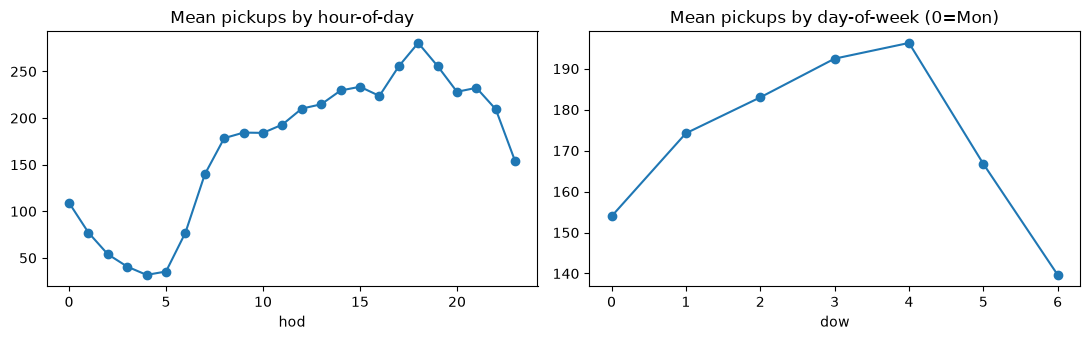

In [14]:
by_hour_of_day = (
    zone_hour.assign(hod=zone_hour.hour.dt.hour).groupby("hod").pickups.mean()
)
by_dow = (
    zone_hour.assign(dow=zone_hour.hour.dt.day_of_week).groupby("dow").pickups.mean()
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
by_hour_of_day.plot(ax=axes[0], marker="o")
axes[0].set_title("Mean pickups by hour-of-day")
by_dow.plot(ax=axes[1], marker="o")
axes[1].set_title("Mean pickups by day-of-week (0=Mon)")
plt.tight_layout()
plt.show()

In [15]:
# One zone's hourly series, to sanity-check 24h / 168h autocorrelation
example_zone = selected_zone_ids[0]
series = (
    zone_hour[zone_hour.PULocationID == example_zone]
    .set_index("hour")["pickups"]
    .asfreq("1h")
    .fillna(0)
)
print(f"zone {example_zone}")
for lag in [1, 24, 168]:
    print(f"  autocorr at lag={lag}h:", round(series.autocorr(lag), 3))

zone 237
  autocorr at lag=1h: 0.958
  autocorr at lag=24h: 0.939
  autocorr at lag=168h: 0.922


## Feature correlation matrix

Causal lag/rolling features (built the same way the feature pipeline will) plus calendar features, across all 20 selected zones' hourly series. Checks for redundant lags/windows and whether calendar features actually carry independent signal, before any of this becomes real pipeline code.

In [16]:
feature_rows = []
for zid in selected_zone_ids:
    s = (
        zone_hour[zone_hour.PULocationID == zid]
        .set_index("hour")["pickups"]
        .asfreq("1h")
        .fillna(0)
    )
    feat = pd.DataFrame({"target": s})
    for lag in [1, 2, 3, 24, 168]:
        feat[f"lag_{lag}"] = s.shift(lag)
    for window in [3, 24, 168]:
        feat[f"roll_{window}"] = s.shift(1).rolling(window).mean()
    feat["hour_of_day"] = feat.index.hour
    feat["day_of_week"] = feat.index.day_of_week
    feat["is_weekend"] = (feat.day_of_week >= 5).astype(int)
    feature_rows.append(feat)

feature_table = pd.concat(feature_rows).dropna()
feature_table.shape

(54716, 12)

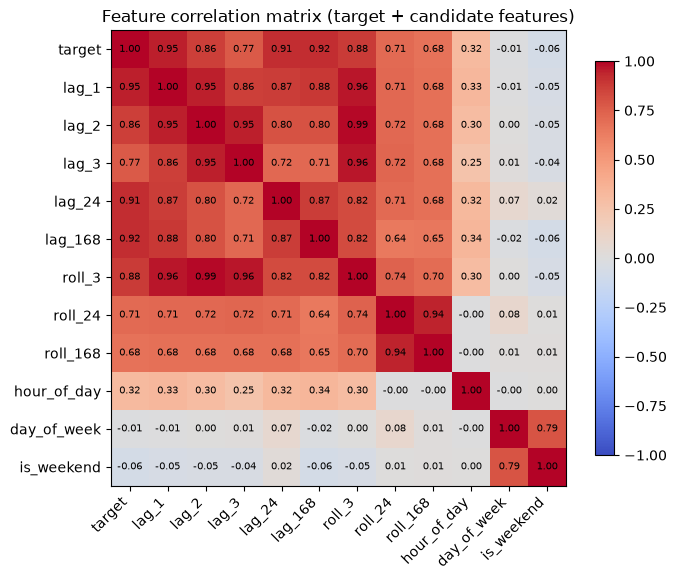

In [17]:
corr = feature_table.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Feature correlation matrix (target + candidate features)")
plt.tight_layout()
plt.show()

## Notes

Fill in after running: schema consistency findings, what (if anything) gets dropped/flagged vs. kept during cleaning, and whether the hour-of-day / day-of-week / lag patterns above actually support the proposed feature set.